# 4. LightGBM — Predicting Airline Satisfaction

El XGBoost de `3_xgboost.ipynb` llegó a **CV AUC = 0,95858**, +0,0095 sobre el logit. El análisis de
sus predicciones out-of-fold dejó un margen chico pero concreto:

- **Está bien calibrado** y el 4,4 % de las filas tiene errores muy confiados (más de 0,8), que
  probablemente sea ruido de etiqueta del dataset sintético. Lo que queda por ganar está en ordenar
  mejor el ~5 % de casos con probabilidad entre 0,3 y 0,7.
- **Tratar la encuesta como categórica no ayuda a los árboles** (0,95853 contra 0,95875 en un fold), y
  CatBoost tardó 44 minutos por fold sin mejorar (0,95859).
- **LightGBM fue el único que mejoró**: 0,95919 en el mismo fold, en 49 s. Crece hoja por hoja
  (*leaf-wise*) en lugar de nivel por nivel, y con `num_leaves=127` arma ramas profundas sólo donde
  hacen falta.

Este notebook mide eso en los 5 folds y prueba si mezclarlo con XGBoost suma.

- **Mismos folds que `3_xgboost.ipynb`** (misma semilla y mismo target), así que la comparación con
  XGBoost es **pareada**: fold contra fold, que es mucho más sensible que comparar medias.
- **Categóricas nativas** para las cuatro nominales; la encuesta queda numérica. Los 292 nulos de
  `Arrival Delay in Minutes` quedan como NaN.

> **Tiempo de ejecución: ~8 minutos** en CPU: ~3 min la sensibilidad a `num_leaves` (sección 2) y
> ~5 min la CV completa (sección 3).

**Métrica:** ROC AUC — **Dataset:** Playground Series S6E10

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, roc_curve
import time
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (15, 6)
plt.rcParams["figure.dpi"] = 100

SEED    = 42
N_FOLDS = 5

## 1. Carga y Preprocesamiento

In [2]:
train = pd.read_csv("../data/train.csv")
test  = pd.read_csv("../data/test.csv")

TARGET = "satisfaction"

crudas_num = ["Age", "Flight Distance", "Departure Delay in Minutes", "Arrival Delay in Minutes"]
encuesta = ["Inflight wifi service", "Departure/Arrival time convenient", "Ease of Online booking",
            "Gate location", "Food and drink", "Online boarding", "Seat comfort",
            "Inflight entertainment", "On-board service", "Leg room service", "Baggage handling",
            "Checkin service", "Cleanliness"]
crudas_cat = ["Gender", "Customer Type", "Type of Travel", "Class"]
features   = crudas_num + encuesta + crudas_cat

# Dtype categorico con vocabulario compartido entre train y test
for col in crudas_cat:
    dtype = pd.CategoricalDtype(categories=sorted(set(train[col]) | set(test[col])), ordered=False)
    train[col] = train[col].astype(dtype)
    test[col]  = test[col].astype(dtype)

y = train[TARGET].astype(int).values

skf   = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(skf.split(train[features], y))

# OOF de los modelos anteriores, para la comparacion pareada y la mezcla
oof_xgb   = np.load("../models/3_xgboost_oof.npy")
test_xgb  = np.load("../models/3_xgboost_test.npy")
oof_logit = np.load("../models/2_logit_oof.npy")
aucs_xgb  = np.array([roc_auc_score(y[va], oof_xgb[va]) for _, va in folds])

print(f"Train: {train.shape[0]:,} filas | Test: {test.shape[0]:,} filas | Features: {len(features)}")
print(f"Tasa base: {y.mean():.4%}")
print(f"\nAUC de XGBoost por fold (recalculado del OOF): {np.round(aucs_xgb, 5)}")
print(f"Media: {aucs_xgb.mean():.5f}  (3_xgboost.ipynb: 0.95858)")

Train: 699,635 filas | Test: 299,844 filas | Features: 21
Tasa base: 44.3573%

AUC de XGBoost por fold (recalculado del OOF): [0.95875 0.95742 0.95941 0.95845 0.95886]
Media: 0.95858  (3_xgboost.ipynb: 0.95858)


## 2. Sensibilidad a `num_leaves`

`num_leaves` es el parámetro que más cambia el comportamiento de LightGBM: controla cuánta
interacción puede representar cada árbol. Se prueban tres valores **sólo en el fold 1** (el mismo
de la prueba previa) para elegir uno antes de correr la CV completa.

In [3]:
BASE = dict(
    objective="binary",
    n_estimators=5000,          # techo; el early stopping corta mucho antes
    learning_rate=0.05,
    min_child_samples=40,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.7,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    verbose=-1,
)


def entrenar(params, tr_idx, va_idx):
    modelo = lgb.LGBMClassifier(**params)
    modelo.fit(train[features].iloc[tr_idx], y[tr_idx],
               eval_set=[(train[features].iloc[va_idx], y[va_idx])], eval_metric="auc",
               callbacks=[lgb.early_stopping(150, verbose=False)])
    return modelo


tr_idx, va_idx = folds[0]
sens = {}
for hojas in [63, 127, 255]:
    t = time.time()
    m = entrenar({**BASE, "num_leaves": hojas}, tr_idx, va_idx)
    sens[hojas] = roc_auc_score(y[va_idx], m.predict_proba(train[features].iloc[va_idx])[:, 1])
    print(f"  num_leaves = {hojas:<4} AUC fold 1 = {sens[hojas]:.5f}  |  "
          f"arboles = {m.best_iteration_:<5}  |  {time.time() - t:.0f}s", flush=True)

HOJAS = max(sens, key=sens.get)
print(f"\nXGBoost en el fold 1: {aucs_xgb[0]:.5f}")
print(f"Elegido: num_leaves = {HOJAS}")

  num_leaves = 63   AUC fold 1 = 0.95893  |  arboles = 750    |  99s
  num_leaves = 127  AUC fold 1 = 0.95919  |  arboles = 244    |  60s
  num_leaves = 255  AUC fold 1 = 0.95927  |  arboles = 182    |  58s

XGBoost en el fold 1: 0.95875
Elegido: num_leaves = 255


## 3. Validación Cross-Validation

Early stopping por fold, predicciones out-of-fold reales y predicción de test promediada entre los 5
modelos.

In [4]:
PARAMS = {**BASE, "num_leaves": HOJAS}

oof      = np.zeros(len(train), dtype=np.float32)
test_sum = np.zeros(len(test), dtype=np.float32)
aucs, iters, modelos = [], [], []

print(f"{'='*66}")
print(f"CROSS-VALIDATION - LightGBM (num_leaves = {HOJAS})")
print(f"{'='*66}")
for fold, (tr_idx, va_idx) in enumerate(folds, 1):
    m = entrenar(PARAMS, tr_idx, va_idx)
    oof[va_idx] = m.predict_proba(train[features].iloc[va_idx])[:, 1]
    test_sum   += m.predict_proba(test[features])[:, 1]
    aucs.append(roc_auc_score(y[va_idx], oof[va_idx]))
    iters.append(m.best_iteration_)
    modelos.append(m)
    print(f"  Fold {fold}: AUC = {aucs[-1]:.5f}  |  best_iteration = {iters[-1]}", flush=True)

aucs       = np.array(aucs)
proba_test = test_sum / N_FOLDS
cv_mean    = aucs.mean()
print(f"{'='*66}")
print(f"  Media: {cv_mean:.5f} +/- {aucs.std():.5f}")
print(f"  AUC out-of-fold: {roc_auc_score(y, oof):.5f}")
print(f"  Arboles usados (media): {np.mean(iters):.0f}")
print(f"{'='*66}")

CROSS-VALIDATION - LightGBM (num_leaves = 255)
  Fold 1: AUC = 0.95927  |  best_iteration = 182
  Fold 2: AUC = 0.95789  |  best_iteration = 210
  Fold 3: AUC = 0.95961  |  best_iteration = 200
  Fold 4: AUC = 0.95907  |  best_iteration = 162
  Fold 5: AUC = 0.95907  |  best_iteration = 230
  Media: 0.95898 +/- 0.00058
  AUC out-of-fold: 0.95897
  Arboles usados (media): 197


## 4. Comparación Pareada con XGBoost

Las dos CV usan exactamente los mismos folds, así que la diferencia se mide fold a fold. El desvío
entre folds (~0,0007) mezcla la dificultad de cada fold con la diferencia entre modelos; el desvío
de la diferencia pareada aísla sólo lo segundo.

In [5]:
dif = aucs - aucs_xgb
t_stat, p_val = stats.ttest_rel(aucs, aucs_xgb)

print(pd.DataFrame({"xgboost": aucs_xgb, "lightgbm": aucs, "diferencia": dif},
                   index=[f"fold {i}" for i in range(1, N_FOLDS + 1)]).round(5).to_string())
print(f"\nDiferencia media: {dif.mean():+.5f}  |  desvio de la diferencia: {dif.std(ddof=1):.5f}")
print(f"LightGBM gana en {(dif > 0).sum()} de {N_FOLDS} folds  |  t pareado = {t_stat:.2f}  (p = {p_val:.4f})")
print(f"\nCorrelacion de Spearman OOF lightgbm vs xgboost: "
      f"{pd.Series(oof).corr(pd.Series(oof_xgb), method='spearman'):.4f}")

        xgboost  lightgbm  diferencia
fold 1  0.95875   0.95927     0.00052
fold 2  0.95742   0.95789     0.00047
fold 3  0.95941   0.95961     0.00020
fold 4  0.95845   0.95907     0.00061
fold 5  0.95886   0.95907     0.00022

Diferencia media: +0.00040  |  desvio de la diferencia: 0.00019
LightGBM gana en 5 de 5 folds  |  t pareado = 4.85  (p = 0.0083)

Correlacion de Spearman OOF lightgbm vs xgboost: 0.9722


## 5. Mezcla con XGBoost

Se promedian **rankings** (no probabilidades): el AUC sólo depende del orden, y así ninguno de los
dos modelos domina por tener probabilidades más extremas. El peso se elige sobre el OOF, entre 0
(LightGBM solo) y 0,9.

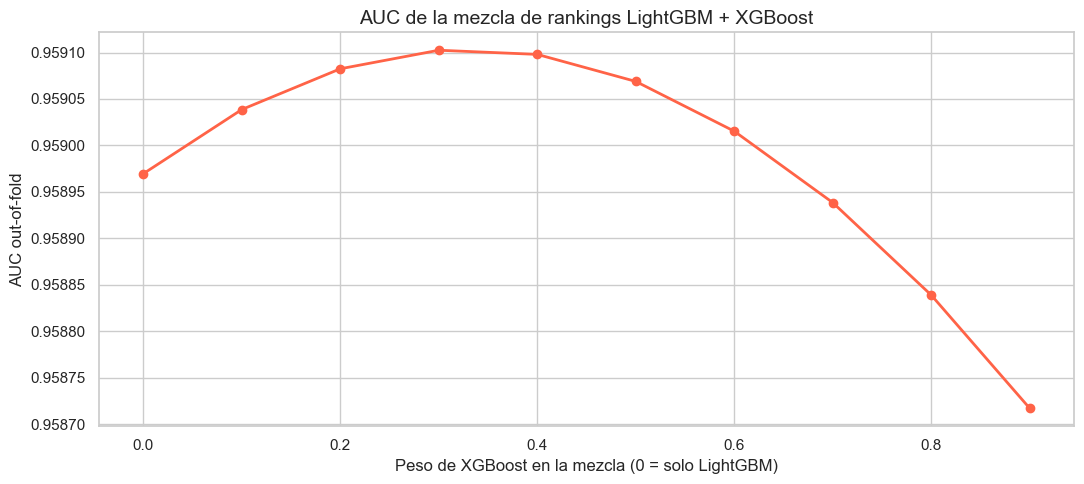

  peso XGBoost 0.0: AUC OOF = 0.95897
  peso XGBoost 0.1: AUC OOF = 0.95904
  peso XGBoost 0.2: AUC OOF = 0.95908
  peso XGBoost 0.3: AUC OOF = 0.95910
  peso XGBoost 0.4: AUC OOF = 0.95910
  peso XGBoost 0.5: AUC OOF = 0.95907
  peso XGBoost 0.6: AUC OOF = 0.95902
  peso XGBoost 0.7: AUC OOF = 0.95894
  peso XGBoost 0.8: AUC OOF = 0.95884
  peso XGBoost 0.9: AUC OOF = 0.95872

Mejor peso de XGBoost: 0.3  ->  AUC OOF 0.95910 (LightGBM solo: 0.95897)
Mezcla por fold: [0.95939 0.95799 0.9598  0.95913 0.95924]  |  gana a LightGBM en 5 de 5 folds


In [6]:
r_lgb = pd.Series(oof).rank(pct=True).values
r_xgb = pd.Series(oof_xgb).rank(pct=True).values

# Hasta 0.9: con peso 1 la "mezcla" seria XGBoost puro, que ya tiene su propia submission
pesos  = np.round(np.arange(0, 0.91, 0.1), 1)
mezcla = {w: roc_auc_score(y, (1 - w) * r_lgb + w * r_xgb) for w in pesos}

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(list(mezcla), list(mezcla.values()), marker="o", color="tomato", lw=2)
ax.set_xlabel("Peso de XGBoost en la mezcla (0 = solo LightGBM)")
ax.set_ylabel("AUC out-of-fold")
ax.set_title("AUC de la mezcla de rankings LightGBM + XGBoost", fontsize=14)
plt.tight_layout()
plt.show()

W_XGB    = max(mezcla, key=mezcla.get)
oof_mix  = (1 - W_XGB) * r_lgb + W_XGB * r_xgb
aucs_mix = np.array([roc_auc_score(y[va], oof_mix[va]) for _, va in folds])

for w, a in mezcla.items():
    print(f"  peso XGBoost {w:.1f}: AUC OOF = {a:.5f}")
print(f"\nMejor peso de XGBoost: {W_XGB}  ->  AUC OOF {mezcla[W_XGB]:.5f} "
      f"(LightGBM solo: {mezcla[0.0]:.5f})")
print(f"Mezcla por fold: {np.round(aucs_mix, 5)}  |  gana a LightGBM en "
      f"{(aucs_mix > aucs).sum()} de {N_FOLDS} folds")

## 6. Diagnóstico por Segmento

In [7]:
seg = pd.DataFrame({"y": y, "logit": oof_logit, "xgb": oof_xgb, "lgbm": oof, "mezcla": oof_mix,
                    "travel": train["Type of Travel"].astype(str), "clase": train["Class"].astype(str)})
tabla = seg.groupby(["travel", "clase"]).apply(lambda g: pd.Series(
    {"n": len(g), **{m: roc_auc_score(g["y"], g[m]) for m in ["logit", "xgb", "lgbm", "mezcla"]}}))
print(tabla.round(4).to_string())

                                 n   logit     xgb    lgbm  mezcla
travel          clase                                             
Business travel Business  338272.0  0.9188  0.9318  0.9333  0.9334
                Eco       141612.0  0.9175  0.9330  0.9329  0.9333
                Eco Plus   17557.0  0.9187  0.9408  0.9411  0.9414
Personal Travel Business    3940.0  0.7882  0.8026  0.8144  0.8113
                Eco       185792.0  0.8050  0.8279  0.8278  0.8287
                Eco Plus   12462.0  0.8008  0.8274  0.8272  0.8283


## 7. Feature Importance

Importancia por *gain*, promediada entre los 5 modelos y normalizada para que sume 1 (comparable con
la de `3_xgboost.ipynb`).

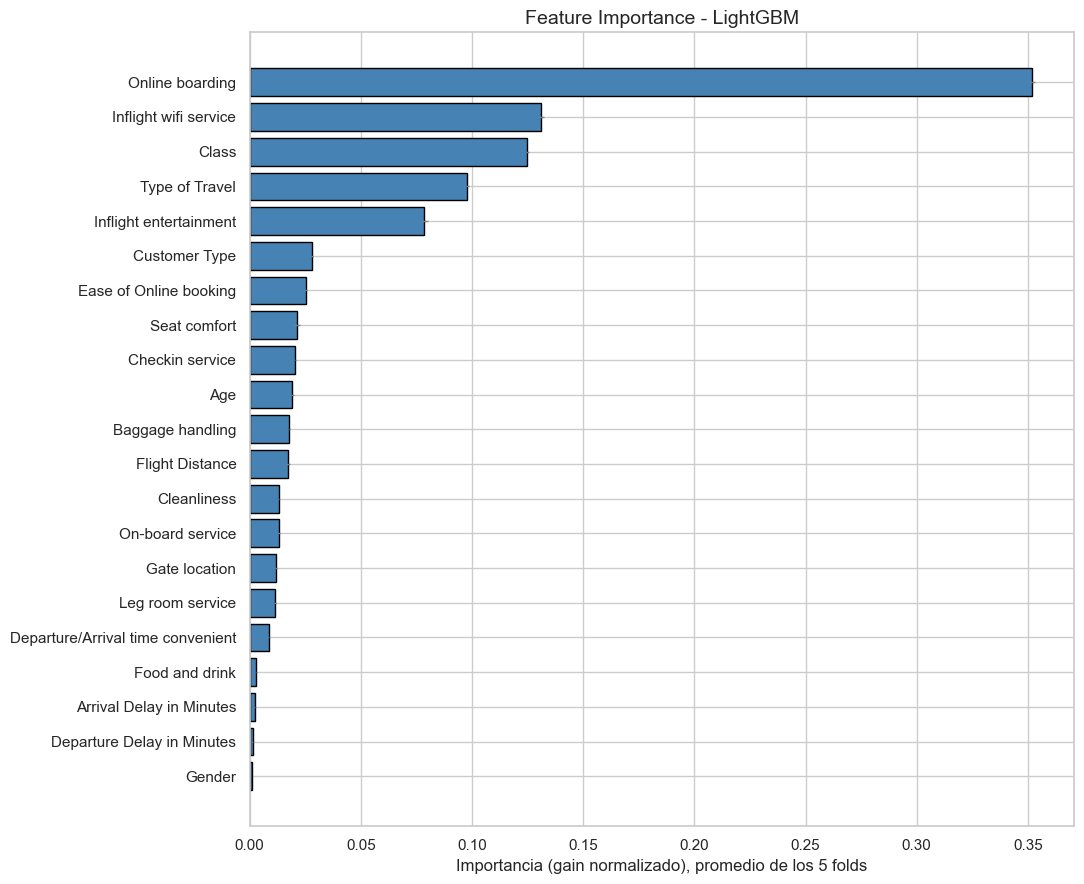

Online boarding                      0.3517
Inflight wifi service                0.1312
Class                                0.1249
Type of Travel                       0.0979
Inflight entertainment               0.0786
Customer Type                        0.0281
Ease of Online booking               0.0252
Seat comfort                         0.0214
Checkin service                      0.0206
Age                                  0.0193
Baggage handling                     0.0179
Flight Distance                      0.0174
Cleanliness                          0.0131
On-board service                     0.0131
Gate location                        0.0118
Leg room service                     0.0114
Departure/Arrival time convenient    0.0086
Food and drink                       0.0031
Arrival Delay in Minutes             0.0023
Departure Delay in Minutes           0.0013
Gender                               0.0011


In [8]:
imps = pd.DataFrame([m.booster_.feature_importance(importance_type="gain") for m in modelos],
                    columns=features)
imps = imps.div(imps.sum(axis=1), axis=0)
imp_media = imps.mean().sort_values()

fig, ax = plt.subplots(figsize=(11, 9))
ax.barh(imp_media.index, imp_media.values, xerr=imps.std().reindex(imp_media.index).values,
        color="steelblue", edgecolor="black", error_kw=dict(ecolor="gray", lw=1))
ax.set_xlabel("Importancia (gain normalizado), promedio de los 5 folds")
ax.set_title("Feature Importance - LightGBM", fontsize=14)
plt.tight_layout()
plt.show()

print(imp_media.sort_values(ascending=False).round(4).to_string())

## 8. Predicción sobre Test y Submission

Se escriben dos submissions, LightGBM solo y la mezcla, y se envía la de mejor AUC out-of-fold. En
test la mezcla usa el mismo peso y el ranking de cada modelo sobre test.

In [9]:
mix_test = ((1 - W_XGB) * pd.Series(proba_test).rank(pct=True).values
            + W_XGB * pd.Series(test_xgb).rank(pct=True).values)

np.save("../models/4_lightgbm_oof.npy",  oof)
np.save("../models/4_lightgbm_test.npy", proba_test)

subs = {
    "lightgbm": ("../submissions/4_lightgbm_submission.csv", proba_test, cv_mean),
    "mezcla":   ("../submissions/4_lgbm_xgb_blend_submission.csv", mix_test, aucs_mix.mean()),
}
for nombre, (ruta, pred, auc) in subs.items():
    pd.DataFrame({"id": test["id"], TARGET: pred}).to_csv(ruta, index=False)
    print(f"{nombre:9s} CV AUC = {auc:.5f}  ->  {ruta}")

ENVIO = "mezcla" if aucs_mix.mean() > cv_mean else "lightgbm"
FILE, _, CV_ENVIO = subs[ENVIO]
print(f"\nSe envia: {ENVIO}")

lightgbm  CV AUC = 0.95898  ->  ../submissions/4_lightgbm_submission.csv
mezcla    CV AUC = 0.95911  ->  ../submissions/4_lgbm_xgb_blend_submission.csv

Se envia: mezcla


In [10]:
# Chequeo de sanidad contra sample_submission (formato e ids)
sample = pd.read_csv("../data/sample_submission.csv")
for ruta, _, _ in subs.values():
    sub = pd.read_csv(ruta)
    assert list(sub.columns) == list(sample.columns), "columnas no coinciden"
    assert len(sub) == len(sample), "cantidad de filas no coincide"
    assert (sub["id"].values == sample["id"].values).all(), "los ids no estan alineados"
    assert sub[TARGET].between(0, 1).all(), "hay probabilidades fuera de [0, 1]"
    assert sub[TARGET].notna().all(), "hay nulos en la prediccion"
print("Chequeos OK - submissions listas para enviar.")

Chequeos OK - submissions listas para enviar.


## 9. Envío a Kaggle vía API

In [11]:
COMPETITION = "playground-series-s6e10"
MSG = (f"LightGBM leaves={HOJAS}" + (f" + XGB rank blend w={W_XGB}" if ENVIO == "mezcla" else "")
       + f" - CV AUC={CV_ENVIO:.5f}")

!kaggle competitions submit -c {COMPETITION} -f "{FILE}" -m "{MSG}"

9 submissions remaining today.
Successfully submitted to Predicting Airline Satisfaction



  0%|          | 0.00/7.80M [00:00<?, ?B/s]
  0%|          | 16.0k/7.80M [00:00<00:57, 141kB/s]
  7%|▋         | 544k/7.80M [00:00<00:06, 1.11MB/s]
  8%|▊         | 640k/7.80M [00:00<00:10, 736kB/s] 
 11%|█▏        | 912k/7.80M [00:01<00:07, 988kB/s]
 18%|█▊        | 1.41M/7.80M [00:01<00:03, 1.77MB/s]
 55%|█████▍    | 4.28M/7.80M [00:01<00:00, 7.59MB/s]
 79%|███████▉  | 6.19M/7.80M [00:01<00:00, 10.3MB/s]
 97%|█████████▋| 7.55M/7.80M [00:01<00:00, 10.0MB/s]
100%|██████████| 7.80M/7.80M [00:01<00:00, 4.12MB/s]


In [12]:
# Score publico de los envios (esperar unos segundos a que Kaggle lo puntue)
!kaggle competitions submissions -c {COMPETITION}

     ref  fileName                         date                        description                                                  status                     publicScore  privateScore  
--------  -------------------------------  --------------------------  -----------------------------------------------------------  -------------------------  -----------  ------------  
57500494  4_lgbm_xgb_blend_submission.csv  2026-10-21 23:46:35.013000  LightGBM leaves=255 + XGB rank blend w=0.3 - CV AUC=0.95911  SubmissionStatus.PENDING                              
57370373  3_xgboost_submission.csv         2026-10-18 22:04:16.173000  XGBoost - crudas - cat nativas - CV AUC=0.95858              SubmissionStatus.COMPLETE  0.95820                    
57027840  2_logit_submission.csv           2026-10-10 02:02:02.677000  Logit - E. D + cruces de viaje - C=0.1 - CV AUC=0.94908      SubmissionStatus.COMPLETE  0.94857                    


## 10. Conclusiones

- **CV AUC = 0,95898** (± 0,00058 entre folds) y 0,95897 out-of-fold, con `num_leaves=255` y las mismas 21 features crudas que XGBoost. El early stopping cortó en 197 árboles de media.
- **`num_leaves` importa poco por encima de 127**: en el fold 1 dio 0,95893 / 0,95919 / 0,95927 con 63 / 127 / 255 hojas. Con más hojas hacen falta menos árboles (750 → 182) y el ajuste es más rápido.
- **+0,00040 sobre XGBoost, y la mejora es real**: LightGBM gana en los 5 de 5 folds, con un desvío de la diferencia pareada de 0,00019 y un t pareado de 4,85 (p = 0,008). La diferencia es menor que el desvío entre folds (0,0006), así que sin la comparación pareada no se habría podido distinguir del ruido. El fold 1 se usó para elegir `num_leaves`, pero en los folds 2-5 la ventaja se mantiene (+0,0002 a +0,0006).
- **La mezcla 70/30 con XGBoost suma +0,00013** (0,95911) y le gana a LightGBM solo en los 5 folds, pero es una ganancia mínima. Los dos modelos ordenan casi igual (Spearman 0,972), mucho más parecido que XGBoost y el logit (0,887). Con pesos de XGBoost por encima de 0,5 el AUC ya baja.
- **Los viajes personales siguen siendo el techo**: 0,81-0,83 de AUC contra 0,93-0,94 en viajes de trabajo, con cualquiera de los tres modelos de árboles. LightGBM sólo mejora claramente a XGBoost en el segmento personal en Business (0,8144 contra 0,8026), que tiene apenas 3.940 filas.
- **La importancia se reparte distinto que en XGBoost**: `Online boarding` sigue primera (35 %), pero `Inflight wifi service` (13 %) y `Class` (12 %) quedan por encima de `Type of Travel` (10 %), que en XGBoost era la segunda con 23 %. Los árboles hoja por hoja reparten los cortes de tipo de viaje entre ramas en lugar de concentrarlos en la raíz.
- **El leaderboard sigue a la CV**: XGBoost dio 0,95820 de score público contra 0,95858 de CV (0,00038 por debajo) y el logit 0,94857 contra 0,94908 (0,00051 por debajo). La mezcla quedó pendiente de puntuación al momento de ejecutar.